In [2]:
# 1: Instala as bibliotecas necessárias para rodar o modelo BERTimbau
!pip install -U transformers datasets scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 111.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 35.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 155.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 MB 62.8 MB/s  0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.0
    Uninstalling transformers-5.22.0:
      Successfully uninstalled transformers-5.22.0
   ━━━━━━━━━━━━━━━━━

In [3]:
# 2: Importando as bibliotecas necessárias para:
# - Manipulação de dados (pandas)
# - PyTorch (torch)
# - Divisão de dados e métricas (scikit-learn)
# - Transformers para modelo BERT
# - Visualização de dados (matplotlib, seaborn)

import os
import json
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from transformers import (
    BertTokenizer,
    BertForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
# 3: Desativar Weights & Biases
# Essa variável de ambiente desliga esse log para evitar pedir login/integração.
os.environ["WANDB_DISABLED"] = "true"


In [5]:
# 4: Funções auxiliares para carregamento de dados
# Função para carregar arquivo .jsonl
def load_jsonl(filepath):
    """Carrega um arquivo .jsonl de forma segura para DataFrame."""

    # Verifica se o arquivo existe; se não, lança erro claro
    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Arquivo {filepath} não encontrado!")

    # Lê o arquivo .jsonl (um JSON por linha) e empilha cada linha em uma lista de dicts
    with open(filepath, "r", encoding="utf-8") as f:
        data = [json.loads(line) for line in f]

    # Converte a lista de dicts em um DataFrame pandas
    return pd.DataFrame(data)

# Função para carregar arquivo .csv
def load_csv(filepath):
    """Carrega um arquivo .csv de forma segura para DataFrame."""

    # Mesma checagem de existência do arquivo para ajudar no debug
    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Arquivo {filepath} não encontrado!")

    # Usa pandas para ler .csv (detecta header e separador automaticamente, na maioria dos casos)
    return pd.read_csv(filepath)


In [6]:
# Use essa célula para verificar onde estão os arquivos de treino e teste e garantir que a célula 5 esteja com o caminho adequado
# import os

# print("Diretório atual:", os.getcwd())
# print("\nArquivos disponíveis:")

# for arquivo in os.listdir("/content"):
#     print(arquivo)

In [7]:
# 5: Carregar os dados
# Aqui carregamos os arquivos de treino e teste no formato DataFrame
train_df = load_jsonl("train.jsonl")
test_df = load_csv("test.csv")


In [8]:
# 6: Subamostragem (essa parte foi utilizada apenas no início)
# Reduzimos o tamanho do dataset para acelerar o treino
# Diminui o tamanho do conjunto de treino para acelerar experimentos.
# - n=3000: pega 3000 linhas aleatórias
#train_df = train_df.sample(n=3000, random_state=42).reset_index(drop=True)


In [9]:
# 7: Criar coluna 'input_text' dinamicamente
# Combina as colunas headline e text em uma única coluna para o modelo usar
# Como têm aguns datasets que  trazem 'headline', outros 'text' (ou os dois), essa função vai criar uma coluna única 'input_text' concatenando o que existir.
def combine_text(df):
    """Cria coluna input_text a partir das colunas disponíveis (headline/text)."""

    # Flags para saber se as colunas existem
    headline_exists = "headline" in df.columns
    text_exists = "text" in df.columns

    # Se a coluna existir, garante string e preenche NaN com vazio
    if headline_exists:
        df["headline"] = df["headline"].fillna("").astype(str)
    if text_exists:
        df["text"] = df["text"].fillna("").astype(str)

    # Os cenários possíveis são:
    # 1. Tem headline e text: concatenamos ambos com rótulos descritivos
    if headline_exists and text_exists:
        df["input_text"] = "headline: " + df["headline"] + " text: " + df["text"]

    # 2. Só headline
    elif headline_exists:
        df["input_text"] = "headline: " + df["headline"]

    # 3. Só text
    elif text_exists:
        df["input_text"] = "text: " + df["text"]

    # 4. Nenhum: erro claro para o usuário ajustar o dataset
    else:
        raise ValueError("Nenhuma das colunas 'headline' ou 'text' encontrada!")
    return df

# Aplica a função em treino e teste para padronizar a entrada do modelo
train_df = combine_text(train_df)
test_df = combine_text(test_df)


In [10]:
# 8: Separar treino e validação
# Precisa dividir o conjunto de treino em 80% treino e 20% validação
train_texts, val_texts, train_labels, val_labels = train_test_split(
    train_df["input_text"].astype(str),
    train_df["label"],
    test_size=0.2,
    random_state=42,
    stratify=train_df["label"]  #estratifica por classe
)

# Extrai os textos do conjunto de teste (separa os textos do conjunto de teste (sem labels))
test_texts = test_df["input_text"].astype(str)


In [11]:
# 9: Tokenização
# Converte textos para IDs numéricos que o modelo BERT entende
# truncation=True: corta textos longos no limite 'max_length'
# padding=True: preenche textos curtos com padding para ter mesmo tamanho no batch
# max_length=512: limite padrão do BERT base
print("Carregando tokenizer BERTimbau...")
tokenizer = BertTokenizer.from_pretrained("neuralmind/bert-base-portuguese-cased")

# Aplica o tokenizer nos três conjuntos (treino, validação e teste)
train_encodings = tokenizer(list(train_texts), truncation=True, padding=True, max_length=128)
val_encodings   = tokenizer(list(val_texts),   truncation=True, padding=True, max_length=128)
test_encodings  = tokenizer(list(test_texts),  truncation=True, padding=True, max_length=128)


Carregando tokenizer BERTimbau...


tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [12]:
# 10: Dataset customizado
# Cria uma classe para armazenar os dados tokenizados no formato PyTorch
class IronyDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels=None):

        # labels: None (no teste) ou lista de rótulos (no treino/validação)
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        # Monta um "item" (um exemplo) no formato de tensores PyTorch
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}

        # Se houver rótulos (treino/validação), inclui sob a chave "labels"
        if self.labels is not None:
            item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        # Tamanho do dataset = número de sequências (len de input_ids)
        return len(self.encodings["input_ids"])

# Cria os datasets para cada divisão
train_dataset = IronyDataset(train_encodings, list(train_labels))
val_dataset = IronyDataset(val_encodings, list(val_labels))
test_dataset = IronyDataset(test_encodings)


In [13]:
# 11: Carregar modelo BERTimbau
# Baixa o modelo pré-treinado BERTimbau com 2 classes (ironia e não ironia)
from transformers import BertConfig

config = BertConfig.from_pretrained(
    "neuralmind/bert-base-portuguese-cased",
    num_labels=2,
    hidden_dropout_prob=0.2,   # Dropout alto
    attention_probs_dropout_prob=0.2
)

model = BertForSequenceClassification.from_pretrained(
    "neuralmind/bert-base-portuguese-cased",
    config=config
)


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

In [14]:
# 12: Métrica de avaliação
# Define a métrica para avaliação: Acurácia (proporção de acertos)
def compute_metrics(eval_pred):
    # eval_pred vem como (logits, labels): logits são as saídas antes do softmax
    logits, labels = eval_pred

    # Pega a classe de maior logit (argmax) como predição
    preds = logits.argmax(axis=1)

    # Compara com os labels verdadeiros para calcular acurácia
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc}


In [15]:
import transformers
import inspect

print("Versão do Transformers:", transformers.__version__)
print("\nParâmetros aceitos:")
print(inspect.signature(TrainingArguments.__init__))

Versão do Transformers: 5.22.1

Parâmetros aceitos:
(self, output_dir: str | None = None, per_device_train_batch_size: int = 8, num_train_epochs: float = 3.0, max_steps: int = -1, learning_rate: float = 5e-05, lr_scheduler_type: transformers.trainer_utils.SchedulerType | str = 'linear', lr_scheduler_kwargs: dict | str | None = None, warmup_steps: float = 0, optim: transformers.training_args.OptimizerNames | str = 'adamw_torch_fused', optim_args: str | None = None, weight_decay: float = 0.0, adam_beta1: float = 0.9, adam_beta2: float = 0.999, adam_epsilon: float = 1e-08, optim_target_modules: None | str | list[str] = None, gradient_accumulation_steps: int = 1, average_tokens_across_devices: bool = True, max_grad_norm: float = 1.0, label_smoothing_factor: float = 0.0, bf16: bool = False, fp16: bool = False, bf16_full_eval: bool = False, fp16_full_eval: bool = False, tf32: bool | None = None, gradient_checkpointing: bool = False, gradient_checkpointing_kwargs: dict[str, typing.Any] | str 

In [16]:
# 13: Configurações do treinamento
# Define os parâmetros para o processo de treinamento

training_args = TrainingArguments(
    output_dir="./results",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    learning_rate=2e-5,
    lr_scheduler_type="linear",
    logging_steps=100,
    report_to="none"
)

In [18]:
# 14: Trainer
# Configura o Hugging Face Trainer com modelo, dados e métricas

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
    data_collator=DataCollatorWithPadding(tokenizer)
)

In [19]:
# 15: Treinamento
# Inicia o treinamento do modelo
print("\n Iniciando o treinamento...")
trainer.train()
print("Treinamento concluído!")



 Iniciando o treinamento...


Step,Training Loss
100,0.291862
200,0.134582
300,0.096909
400,0.078070
500,0.073019
600,0.081704
700,0.057616
800,0.065076
900,0.047299
1000,0.031036


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Treinamento concluído!


In [20]:
# 16: Avaliação final
# Avalia o modelo no conjunto de validação
print("\n Avaliando o modelo no conjunto de validação...")
eval_result = trainer.evaluate()
print(f"Acurácia final: {eval_result['eval_accuracy']:.4f}")



 Avaliando o modelo no conjunto de validação...


Training Loss,Validation Loss,Step,Accuracy
0.004637,0.044542,2775,0.993782


Acurácia final: 0.9938


In [21]:
# 17: Previsão no teste
# Realiza as previsões no conjunto de teste
print("\n Realizando previsões no conjunto de teste...")
predictions = trainer.predict(test_dataset)
preds = predictions.predictions.argmax(axis=1)



 Realizando previsões no conjunto de teste...


Arquivo 'submission.csv' gerado com sucesso!


/tmp/ipykernel_1762/2517016591.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plot_df, x="Classe", y="Quantidade", palette="viridis")


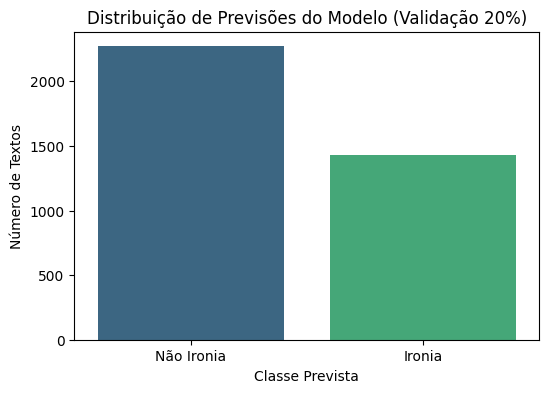

In [22]:
# 18: Geração da submissão e gráfico
# Gera arquivo CSV com previsões
submission = pd.DataFrame({"id": test_df["id"], "label": preds})
submission.to_csv("submission.csv", index=False)
print("Arquivo 'submission.csv' gerado com sucesso!")

#Gráfico usando os 20% de validação

val_predictions = trainer.predict(val_dataset)
val_preds = val_predictions.predictions.argmax(axis=1)

# Cria gráfico com a distribuição das classes previstas na validação
label_counts = pd.Series(val_preds).value_counts().sort_index()
label_names = {0: "Não Ironia", 1: "Ironia"}

plot_df = pd.DataFrame({
    "Classe": [label_names[i] for i in label_counts.index],
    "Quantidade": label_counts.values
})

plt.figure(figsize=(6,4))
sns.barplot(data=plot_df, x="Classe", y="Quantidade", palette="viridis")
plt.title("Distribuição de Previsões do Modelo (Validação 20%)")
plt.xlabel("Classe Prevista")
plt.ylabel("Número de Textos")
plt.show()

